# IT462: Exploratory Data Analysis
## Lab Assignment 12: Clustering — Customer Segmentation with K-Means and Hierarchical Clustering

**Student Name:** PRAJAPATI NEEL  
**Roll Number:** 202611022  
**Course:** IT462 — Exploratory Data Analysis  
**Lab Assignment:** 12 (Customer Segmentation using K-Means and Hierarchical Clustering)  

---
### Assignment Guidelines Followed:
* **Reproducibility:** `random_state=42` and `n_init=10` are configured in every K-Means initialization.
* **Interpretation:** Every visual plot features a descriptive title and labeled axes; every question includes a 1 to 3 line analytical interpretation.
* **Feature Scope:** Clustering is performed strictly on the six annual spending features (`Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`). `Channel` and `Region` are kept aside as ground-truth validation labels.
* **Business Interpretation:** All customer persona profiles are articulated using real monetary spending figures from the raw data (`df`), avoiding scaled or log-transformed figures.
* **File Naming:** Submission files are generated as `IT462_Lab12_202611022.ipynb` and `202611022_lab12.ipynb`, along with their corresponding PDF exports.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram

# Set plot styling for clear academic presentation
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 11

---
## Part A: Understanding the Data
Clustering algorithms operate without ground-truth target labels; therefore, exploratory analysis and understanding the distribution, scales, and relationships within the dataset is critical before applying distance-based algorithms.

### Q1. Load and Inspect the Dataset
Load the Wholesale Customers dataset, verify its shape, data types, the first 5 rows, summary statistics (`df.describe()`), check for missing values and duplicate rows, and visualize the distributions of `Channel` and `Region` using bar charts.

=== Dataset Shape ===
Total Rows (Clients): 440, Total Columns: 8

=== Data Types ===
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

=== First 5 Rows ===


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



=== Summary Statistics (df.describe().round(2)) ===


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00,440.00,440.00
mean,1.32,2.54,12000.30,5796.27,7951.28,3071.93,2881.49,1524.87
std,0.47,0.77,12647.33,7380.38,9503.16,4854.67,4767.85,2820.11
min,1.00,1.00,3.00,55.00,3.00,25.00,3.00,3.00
25%,1.00,2.00,3127.75,1533.00,2153.00,742.25,256.75,408.25
50%,1.00,3.00,8504.00,3627.00,4755.50,1526.00,816.50,965.50
75%,2.00,3.00,16933.75,7190.25,10655.75,3554.25,3922.00,1820.25
max,2.00,3.00,112151.00,73498.00,92780.00,60869.00,40827.00,47943.00



Missing values in dataset: 0
Duplicate rows in dataset: 0


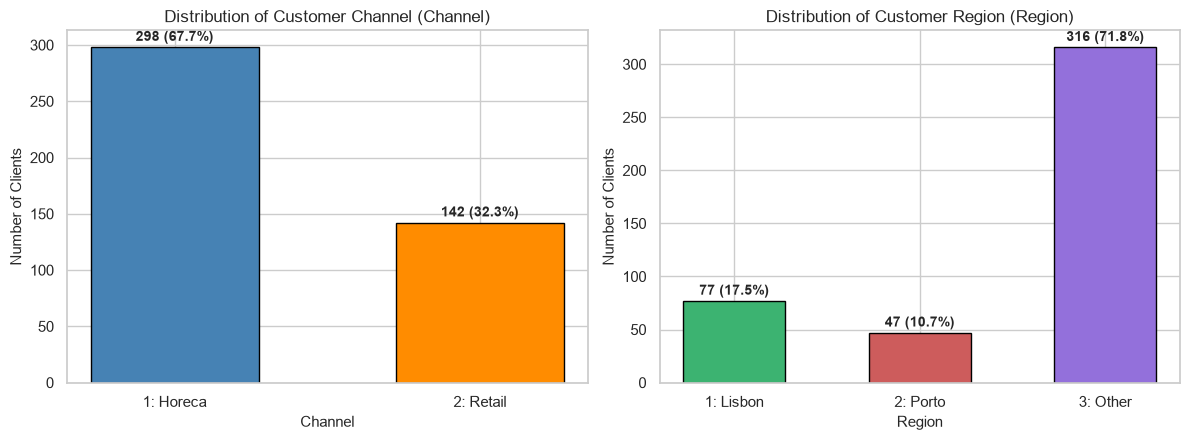

In [2]:
# Load dataset from local copy or UCI repository URL
csv_url = "https://raw.githubusercontent.com/TrainingByPackt/Data-Science-with-Python/master/Chapter01/Data/Wholesale%20customers%20data.csv"
local_csv = "Wholesale customers data.csv"

if os.path.exists(local_csv):
    df = pd.read_csv(local_csv)
else:
    df = pd.read_csv(csv_url)

spend = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

print("=== Dataset Shape ===")
print(f"Total Rows (Clients): {df.shape[0]}, Total Columns: {df.shape[1]}")

print("\n=== Data Types ===")
print(df.dtypes)

print("\n=== First 5 Rows ===")
display(df.head())

print("\n=== Summary Statistics (df.describe().round(2)) ===")
display(df.describe().round(2))

# Check for missing values and duplicate records
missing_vals = df.isnull().sum().sum()
duplicate_rows = df.duplicated().sum()
print(f"\nMissing values in dataset: {missing_vals}")
print(f"Duplicate rows in dataset: {duplicate_rows}")

# Bar charts for Channel and Region
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

channel_counts = df["Channel"].value_counts().sort_index()
channel_labels = ["1: Horeca", "2: Retail"]
bars1 = axes[0].bar(channel_labels, channel_counts.values, color=["steelblue", "darkorange"], edgecolor="black", width=0.55)
axes[0].set_title("Distribution of Customer Channel (Channel)")
axes[0].set_xlabel("Channel")
axes[0].set_ylabel("Number of Clients")
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 3, f"{int(bar.get_height())} ({bar.get_height()/len(df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold")

region_counts = df["Region"].value_counts().sort_index()
region_labels = ["1: Lisbon", "2: Porto", "3: Other"]
bars2 = axes[1].bar(region_labels, region_counts.values, color=["mediumseagreen", "indianred", "mediumpurple"], edgecolor="black", width=0.55)
axes[1].set_title("Distribution of Customer Region (Region)")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Number of Clients")
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 3, f"{int(bar.get_height())} ({bar.get_height()/len(df)*100:.1f}%)", ha="center", va="bottom", fontweight="bold")

plt.tight_layout()
plt.show()

> **Interpretation (Q1):** The dataset comprises 440 Portuguese wholesale clients across 8 integer columns with zero missing values and zero duplicate records. The customer base is heavily weighted toward Horeca establishments (67.7%, 298 clients) compared to Retail shops (32.3%, 142 clients), with over 71.8% of clients operating in regions outside the Lisbon and Porto metropolitan hubs.

### Q2. Spending Distributions, Skewness, and Outlier Analysis
Analyze spending distributions with histograms and boxplots, calculate Pearson skewness, count outliers using the $1.5 \times \text{IQR}$ rule, and assess whether high-spending clients represent errors or genuine commercial clients.

=== Spending Distribution and Outlier Summary ===


,Skewness,Outliers (Count),Outliers (%),Min Spend,Median Spend,Max Spend
Fresh,2.561,20,4.55,3,8504.0,112151
Milk,4.054,28,6.36,55,3627.0,73498
Grocery,3.587,24,5.45,3,4755.5,92780
Frozen,5.908,43,9.77,25,1526.0,60869
Detergents_Paper,3.632,30,6.82,3,816.5,40827
Delicassen,11.152,27,6.14,3,965.5,47943


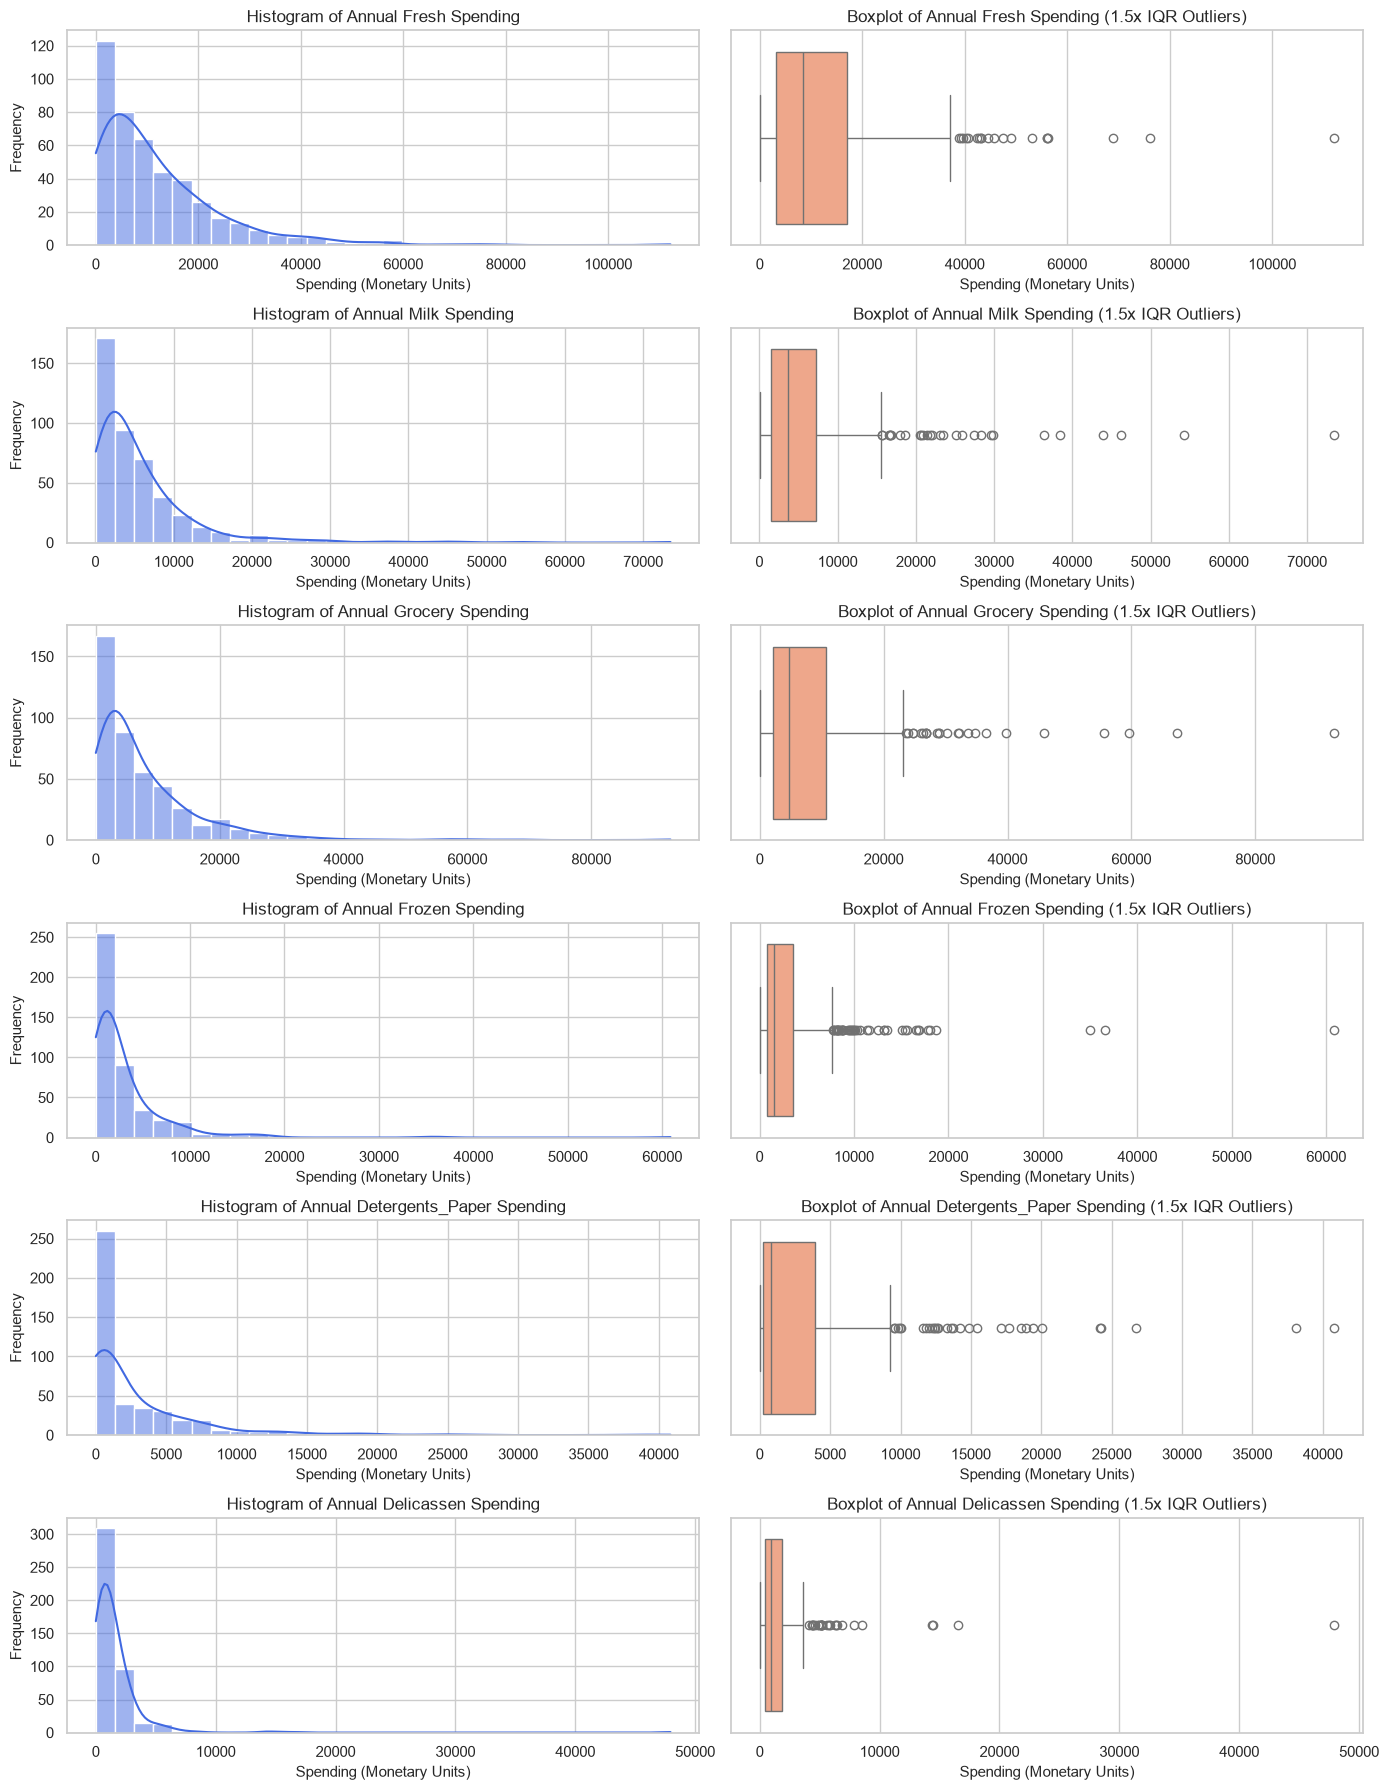

In [3]:
# Compute skewness
skewness = df[spend].skew()

# Compute 1.5 x IQR outliers
q1, q3 = df[spend].quantile(0.25), df[spend].quantile(0.75)
iqr = q3 - q1
outliers = (df[spend] < q1 - 1.5 * iqr) | (df[spend] > q3 + 1.5 * iqr)
outlier_counts = outliers.sum()

outlier_summary = pd.DataFrame({
    "Skewness": skewness.round(3),
    "Outliers (Count)": outlier_counts,
    "Outliers (%)": (outlier_counts / len(df) * 100).round(2),
    "Min Spend": df[spend].min(),
    "Median Spend": df[spend].median(),
    "Max Spend": df[spend].max()
})
print("=== Spending Distribution and Outlier Summary ===")
display(outlier_summary)

# Plot histograms with KDE and boxplots
fig, axes = plt.subplots(6, 2, figsize=(14, 18))
for i, col in enumerate(spend):
    # Histogram
    sns.histplot(df[col], kde=True, ax=axes[i, 0], color="royalblue", bins=30)
    axes[i, 0].set_title(f"Histogram of Annual {col} Spending")
    axes[i, 0].set_xlabel("Spending (Monetary Units)")
    axes[i, 0].set_ylabel("Frequency")

    # Boxplot
    sns.boxplot(x=df[col], ax=axes[i, 1], color="lightsalmon")
    axes[i, 1].set_title(f"Boxplot of Annual {col} Spending (1.5x IQR Outliers)")
    axes[i, 1].set_xlabel("Spending (Monetary Units)")

plt.tight_layout()
plt.show()

> **Interpretation (Q2):** All six spending features exhibit extreme positive right-skewness (ranging from 2.56 for Fresh to 11.15 for Delicassen), demonstrating that the majority of clients spend modest amounts while a small minority purchase at very high volumes. The 1.5 x IQR rule detects 20 to 43 outliers per category; these represent legitimate high-value commercial clients (such as large supermarket chains and luxury hotel resorts) rather than data entry errors.

### Q3. Correlation Heatmap and Channel Purchasing Profiles
Evaluate correlations between the six spending categories to detect key co-purchasing patterns, plot the strongest correlated pair colored by `Channel`, and analyze median spending profiles across Horeca and Retail channels.

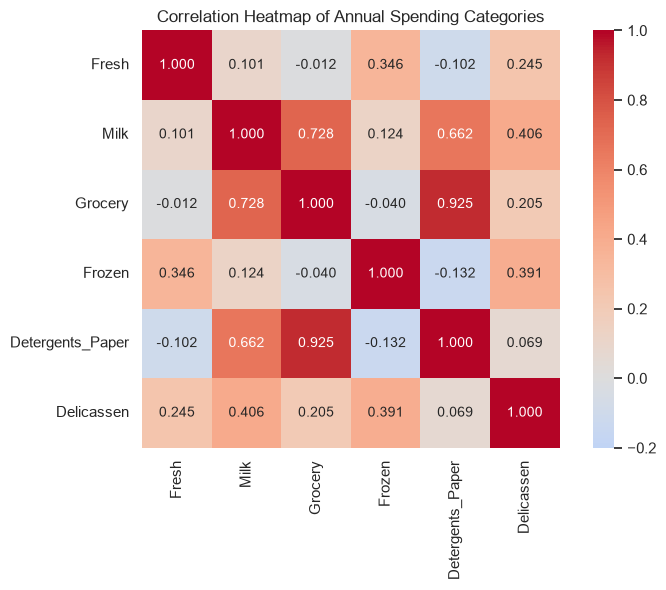

Most strongly correlated pair: Grocery and Detergents_Paper (r = 0.925)


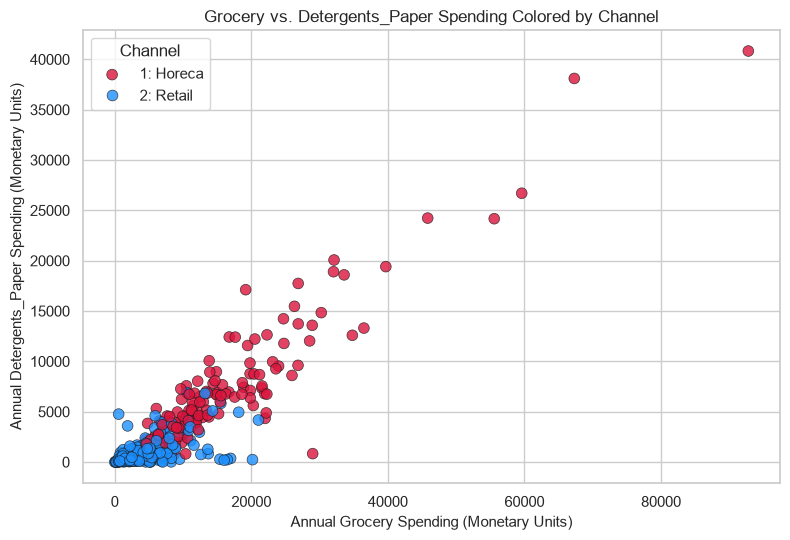

=== Median Spending per Category by Channel ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Channel,,,,,,
1,9581.5,2157.0,2684.0,2057.5,385.5,821.0
2,5993.5,7812.0,12390.0,1081.0,5614.5,1350.0


In [4]:
# Correlation heatmap of the 6 spending columns
plt.figure(figsize=(8, 6))
corr_matrix = df[spend].corr()
sns.heatmap(corr_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0, vmin=-0.2, vmax=1.0, square=True)
plt.title("Correlation Heatmap of Annual Spending Categories")
plt.tight_layout()
plt.show()

# Find most strongly correlated pair
c_unstack = corr_matrix.unstack()
c_unstack = c_unstack[c_unstack < 0.9999]
top_pair = c_unstack.sort_values(ascending=False).index[0]
print(f"Most strongly correlated pair: {top_pair[0]} and {top_pair[1]} (r = {corr_matrix.loc[top_pair[0], top_pair[1]]:.3f})")

# Scatter plot of Grocery vs Detergents_Paper colored by Channel
plt.figure(figsize=(8, 5.5))
scatter = sns.scatterplot(
    data=df, x="Grocery", y="Detergents_Paper", hue="Channel",
    palette={1: "dodgerblue", 2: "crimson"}, alpha=0.8, s=60, edgecolor="k", linewidth=0.5
)
plt.title("Grocery vs. Detergents_Paper Spending Colored by Channel")
plt.xlabel("Annual Grocery Spending (Monetary Units)")
plt.ylabel("Annual Detergents_Paper Spending (Monetary Units)")
plt.legend(title="Channel", labels=["1: Horeca", "2: Retail"])
plt.tight_layout()
plt.show()

# Median spending per category for each channel
print("=== Median Spending per Category by Channel ===")
channel_medians = df.groupby("Channel")[spend].median()
display(channel_medians.round(1))

> **Interpretation (Q3):** `Grocery` and `Detergents_Paper` exhibit the strongest correlation ($r = 0.925$), followed closely by `Grocery` and `Milk` ($r = 0.728$). Typical hotels/restaurants (Horeca) prioritize fresh perishable goods (median Fresh: 9,582, Frozen: 2,058) while buying minimal cleaning paper goods (Detergents_Paper: 386); conversely, retail grocers buy heavily in shelf-stable resale categories (Grocery: 12,390, Milk: 7,812, Detergents_Paper: 5,615).

---
## Part B: Preparing the Data for Clustering
K-Means groups data points based on Euclidean distance. Features with large raw numerical values and extreme right-skewed tails dominate distance calculations, distorting cluster shapes. The pipeline below stabilizes variance and equalizes feature influence.

### Q4. Log Transformation and Standard Scaling
Apply `np.log1p` to compress heavy right tails and `StandardScaler` to normalize feature variances. Verify that the transformed features achieve mean $\approx 0$ and standard deviation $\approx 1$, and explain why skipping these steps would bias clustering toward `Fresh`.

=== Summary Statistics of Preprocessed Data X ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.00,440.00,440.00,440.00,440.00,440.00
mean,0.00,-0.00,-0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-5.00,-3.79,-6.36,-3.16,-3.17,-4.09
25%,-0.47,-0.73,-0.69,-0.54,-0.73,-0.51
50%,0.21,0.07,0.02,0.02,-0.05,0.16
75%,0.68,0.70,0.75,0.68,0.87,0.65
max,1.97,2.86,2.70,2.90,2.24,3.18



=== Skewness Reduction via Log Transformation ===


,Raw Skewness,Log-Transformed Skewness
Fresh,2.561,-1.575
Milk,4.054,-0.224
Grocery,3.587,-0.675
Frozen,5.908,-0.353
Detergents_Paper,3.632,-0.236
Delicassen,11.152,-1.092


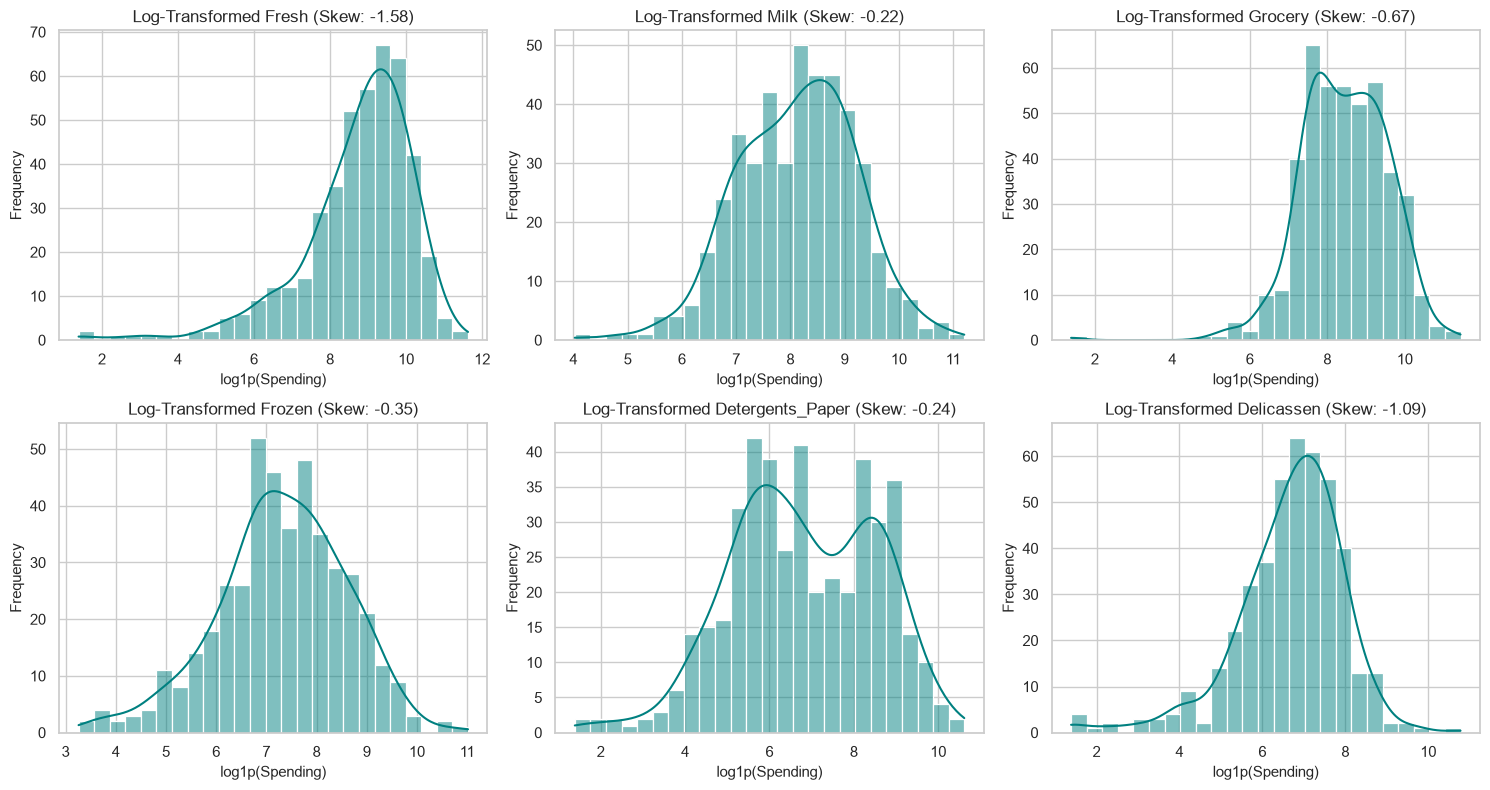

In [5]:
from sklearn.preprocessing import StandardScaler

# Step 1: Log transform using log1p
X_log = np.log1p(df[spend])

# Step 2: Standard scaling (mean 0, std 1)
scaler = StandardScaler()
X = scaler.fit_transform(X_log)

# Verify scaled data properties
scaled_df = pd.DataFrame(X, columns=spend)
print("=== Summary Statistics of Preprocessed Data X ===")
display(scaled_df.describe().round(2))

# Compare skewness before and after log transform
skew_df = pd.DataFrame({
    "Raw Skewness": df[spend].skew().round(3),
    "Log-Transformed Skewness": X_log.skew().round(3)
})
print("\n=== Skewness Reduction via Log Transformation ===")
display(skew_df)

# Visual comparison of raw vs log1p distributions
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(spend):
    ax = axes[i // 3, i % 3]
    sns.histplot(X_log[col], kde=True, ax=ax, color="teal", bins=25)
    ax.set_title(f"Log-Transformed {col} (Skew: {X_log[col].skew():.2f})")
    ax.set_xlabel("log1p(Spending)")
    ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

> **Explanation (Q4):** Without log transformation and scaling, `Fresh`—whose raw values reach 112,151 and whose variance exceeds $1.6 \times 10^8$—would completely dominate Euclidean distance calculations, rendering lower-magnitude features like Detergents_Paper irrelevant. Log transformation compresses the extreme right tail, and standard scaling ensures every spending dimension contributes equally with zero mean and unit variance.

### Q5. 2-D PCA Projection of Customer Spending
Reduce the 6-dimensional prepared dataset $X$ to 2 principal components to visualize the global customer structure in 2D, evaluate explained variance, and observe whether clients form discrete clusters or a continuous manifold.

Explained Variance Ratio by Component: PC1 = 0.441, PC2 = 0.272
Total Information (Variance) Kept: 0.713 (71.3%)


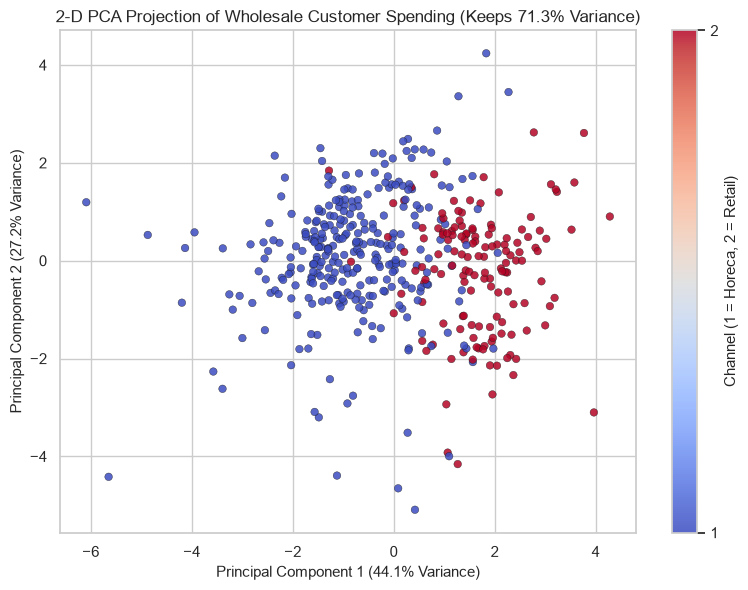

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

exp_var = pca.explained_variance_ratio_
total_var = exp_var.sum()
print(f"Explained Variance Ratio by Component: PC1 = {exp_var[0]:.3f}, PC2 = {exp_var[1]:.3f}")
print(f"Total Information (Variance) Kept: {total_var:.3f} ({total_var * 100:.1f}%)")

# Scatter plot of PCA projection coloured by Channel
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df["Channel"], cmap="coolwarm", s=30, alpha=0.85, edgecolor="k", linewidth=0.3)
cbar = plt.colorbar(scatter, ticks=[1, 2])
cbar.set_label("Channel (1 = Horeca, 2 = Retail)")
plt.title(f"2-D PCA Projection of Wholesale Customer Spending (Keeps {total_var*100:.1f}% Variance)")
plt.xlabel(f"Principal Component 1 ({exp_var[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({exp_var[1]*100:.1f}% Variance)")
plt.tight_layout()
plt.show()

> **Interpretation (Q5):** The two principal components retain 71.3% of the total dataset variance (PC1: 44.1%, PC2: 27.2%). Clients do not split into isolated, distant clusters; rather, they form a cohesive, continuous cloud showing a distinct gradient where Horeca clients concentrate on the negative PC1 side and Retail clients occupy the positive PC1 region with overlap along the center.

---
## Part C: Choosing the Number of Groups
Determining the optimal number of clusters requires evaluating both geometric compactness (Elbow method / Inertia) and cluster separation (Silhouette analysis), joined with practical commercial interpretability.

### Q6. Elbow Method (Inertia vs. k)
Run K-Means for $k = 1$ to 8 using `random_state=42` and `n_init=10`, record within-cluster sum of squares (inertia), and plot the inertia trajectory to detect elbow inflection points.

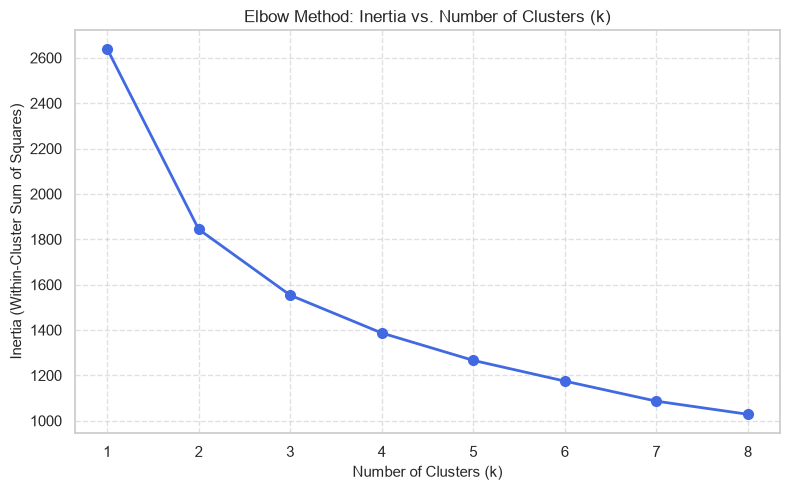

In [7]:
ks = range(1, 9)
inertias = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(ks, inertias, marker="o", color="royalblue", linewidth=2, markersize=7)
plt.title("Elbow Method: Inertia vs. Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(ks)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

> **Interpretation (Q6):** Inertia drops steeply from $k=1$ (2640.0) to $k=2$ (1844.1) and $k=3$ (1553.4), after which the curve levels off with diminishing returns for $k \ge 4$. An elbow region is visible around $k = 2$ and $k = 3$, marking a natural plateau where intra-cluster spread stabilizes.

### Q7. Silhouette Analysis and Final Choice of k
Compute silhouette scores for $k = 2$ to 8, display inertia and silhouette metrics in a unified comparison table, and establish the justification for adopting $k = 3$ for subsequent customer segmentation.

=== Clustering Evaluation Table (k = 2 to 8) ===


,k,Inertia,Silhouette Score
0,2,1844.1,0.290
1,3,1553.4,0.259
2,4,1386.9,0.188
3,5,1266.1,0.192
4,6,1174.8,0.201
5,7,1086.4,0.196
6,8,1028.5,0.185


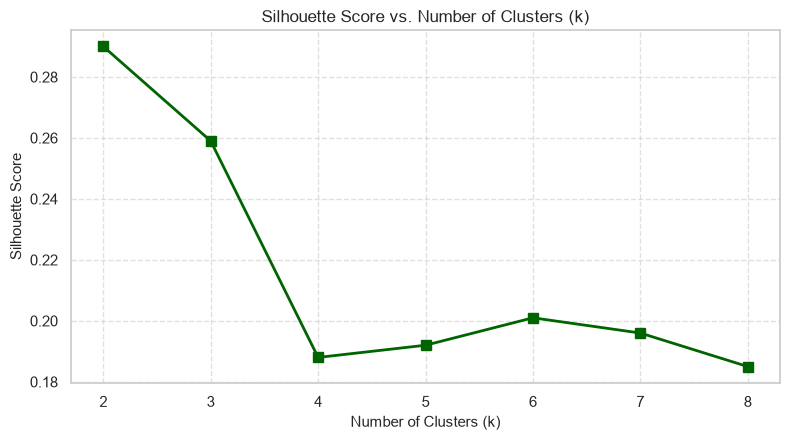

In [8]:
cluster_metrics = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    sil = silhouette_score(X, km.labels_)
    cluster_metrics.append({
        "k": k,
        "Inertia": round(km.inertia_, 1),
        "Silhouette Score": round(sil, 3)
    })

eval_df = pd.DataFrame(cluster_metrics)
print("=== Clustering Evaluation Table (k = 2 to 8) ===")
display(eval_df)

# Plot Silhouette Score vs k
plt.figure(figsize=(8, 4.5))
plt.plot(eval_df["k"], eval_df["Silhouette Score"], marker="s", color="darkgreen", linewidth=2, markersize=7)
plt.title("Silhouette Score vs. Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

> **Interpretation (Q7):** The silhouette score peaks at $k = 2$ (0.290) and remains strong at $k = 3$ (0.259), but drops under 0.202 for $k \ge 4$. We select $k = 3$ because while $k=2$ merely separates fresh foods from shelf goods, $k=3$ delivers superior commercial utility by identifying distinct fresh restaurants, large multi-department enterprises, and small retail stores while maintaining strong mathematical compactness.

---
## Part D: Clustering Models
With $k = 3$ established, we fit K-Means and Hierarchical Clustering models, profile real customer spending across segments, examine spatial cluster arrangements in PCA space, and formulate concrete business strategies.

### Q8. K-Means (k = 3) Group Profiling and Real Spending Heatmap
Fit K-Means with $k = 3$ (`random_state=42`, `n_init=10`), assign the cluster labels to `df['Group']`, print group sizes, calculate median real spending per group from `df`, and display the profile as an annotated heatmap.

=== Group Sizes (Value Counts) ===


,Number of Clients
Group,
0,80
1,147
2,213



=== Median Real Spending per Group (Original Monetary Units) ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group,,,,,,
0,1492.0,6300.0,10502.0,376.0,4218.0,434.0
1,12126.0,7184.0,9965.0,2005.0,3378.0,2005.0
2,9612.0,1601.0,2155.0,2121.0,274.0,686.0


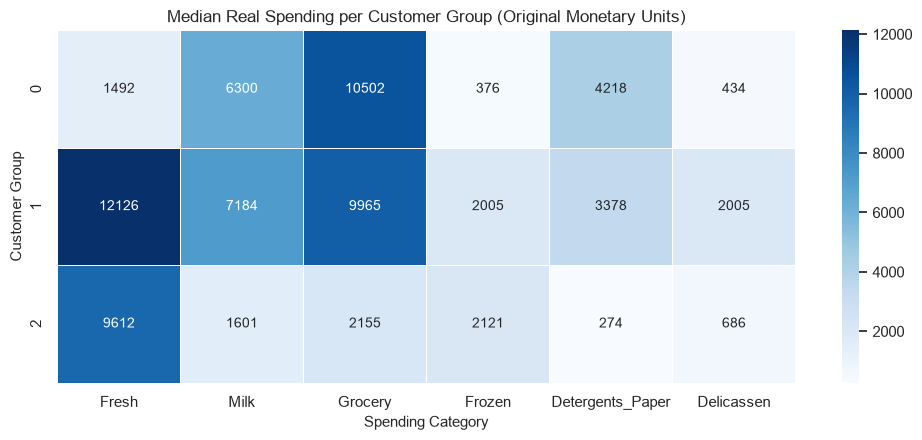

In [9]:
# Fit K-Means with k = 3
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
df["Group"] = km.labels_

print("=== Group Sizes (Value Counts) ===")
group_counts = df["Group"].value_counts().sort_index()
display(group_counts.to_frame("Number of Clients"))

# Median real spending per group (using original unscaled df)
profile = df.groupby("Group")[spend].median().round(0)
print("\n=== Median Real Spending per Group (Original Monetary Units) ===")
display(profile)

# Profile heatmap
plt.figure(figsize=(10, 4.5))
sns.heatmap(profile, annot=True, fmt=".0f", cmap="Blues", cbar=True, linewidths=0.5)
plt.title("Median Real Spending per Customer Group (Original Monetary Units)")
plt.xlabel("Spending Category")
plt.ylabel("Customer Group")
plt.tight_layout()
plt.show()

> **Interpretation (Q8):** Group 2 is the largest segment (213 clients) characterized by high Fresh (9,612) and Frozen (2,121) with very low Detergents_Paper (274); Group 1 (147 clients) represents high-spending accounts across all categories (Fresh 12,126, Grocery 9,965, Milk 7,184); Group 0 (80 clients) spends heavily on Grocery (10,502) and Detergents_Paper (4,218) with minimal Fresh (1,492). Spending in `Detergents_Paper` and `Fresh` creates the primary distinction between Group 0 and Group 2, while overall volume distinguishes Group 1.

### Q9. 2-D PCA Picture Coloured by Cluster Group
Re-plot the 2D PCA projection from Q5 colored by the assigned K-Means cluster `Group` to examine whether the clusters form disjoint regions or share boundaries.

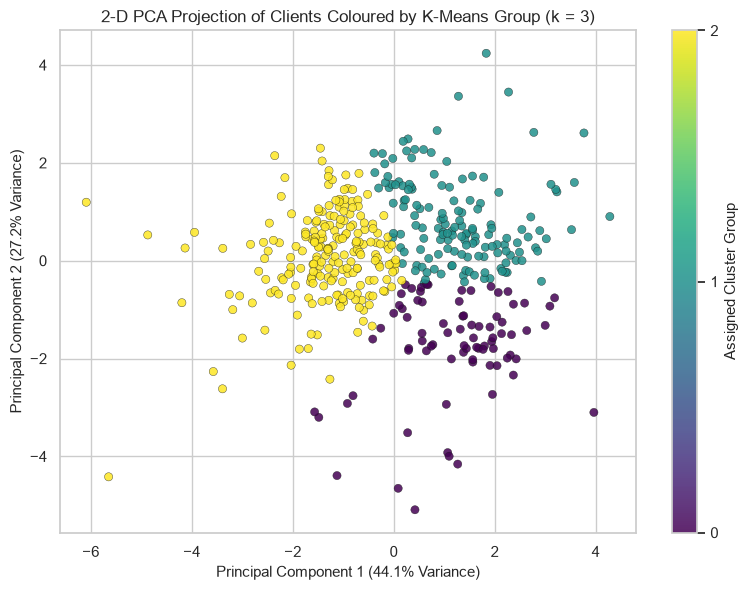

In [10]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df["Group"], cmap="viridis", s=35, alpha=0.85, edgecolor="k", linewidth=0.3)
cbar = plt.colorbar(scatter, ticks=[0, 1, 2])
cbar.set_label("Assigned Cluster Group")
plt.title("2-D PCA Projection of Clients Coloured by K-Means Group (k = 3)")
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.tight_layout()
plt.show()

> **Interpretation (Q9):** The three groups occupy distinct partitions of the 2D PCA plane: Group 2 on the left, Group 0 on the lower-right, and Group 1 in the upper-right region. The groups touch along continuous boundaries rather than forming isolated islands, reflecting the continuous distribution of wholesale purchasing behaviors.

### Q10. Hierarchical Clustering (Ward's Dendrogram and Concordance)
Generate a hierarchical clustering dendrogram with Ward's linkage, determine the horizontal cut height yielding 3 clusters, fit `AgglomerativeClustering(n_clusters=3)`, and assess concordance with K-Means using a cross-tabulation matrix.

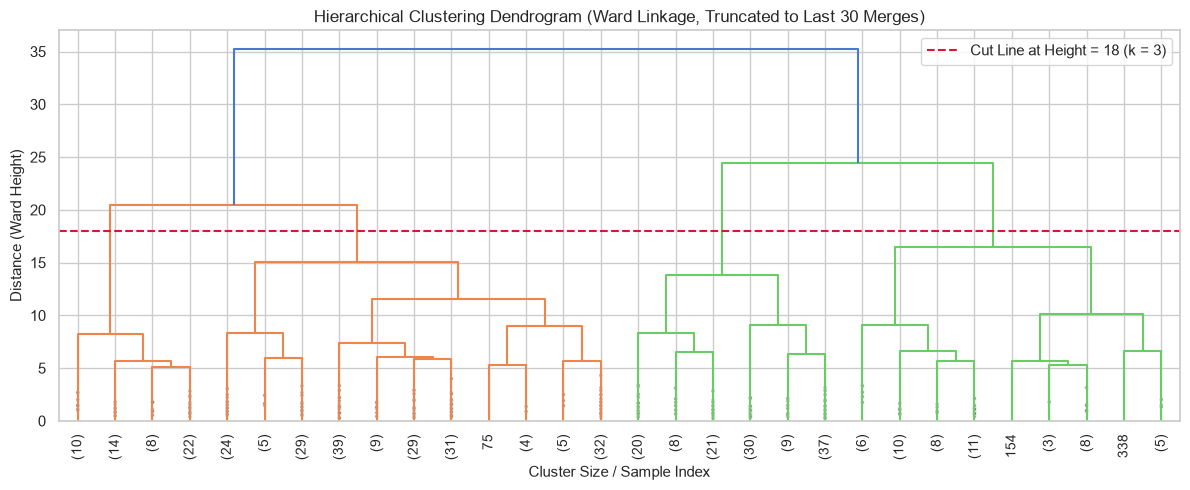

=== Cross-Tabulation: K-Means Groups vs. Agglomerative Clusters ===


Agglomerative Cluster,0,1,2
K-Means Group,,,
0,10,36,34
1,50,6,91
2,202,11,0


In [11]:
# Ward linkage hierarchical clustering
Z = linkage(X, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, leaf_font_size=10, show_contracted=True)
plt.title("Hierarchical Clustering Dendrogram (Ward Linkage, Truncated to Last 30 Merges)")
plt.xlabel("Cluster Size / Sample Index")
plt.ylabel("Distance (Ward Height)")
plt.axhline(y=18, color="crimson", linestyle="--", linewidth=1.5, label="Cut Line at Height = 18 (k = 3)")
plt.legend()
plt.tight_layout()
plt.show()

# Fit Agglomerative Clustering with k = 3
agg = AgglomerativeClustering(n_clusters=3).fit(X)

print("=== Cross-Tabulation: K-Means Groups vs. Agglomerative Clusters ===")
ct_hierarchical = pd.crosstab(km.labels_, agg.labels_, rownames=["K-Means Group"], colnames=["Agglomerative Cluster"])
display(ct_hierarchical)

> **Interpretation (Q10):** A horizontal cut at height $\approx 18$ traverses 3 distinct vertical branches in the dendrogram, confirming 3 natural clusters. The cross-tabulation demonstrates strong agreement: 202 of 213 clients in K-Means Group 2 map directly into Agglomerative Cluster 0 (94.8% overlap), and Group 1 aligns predominantly with Cluster 2, verifying that cluster boundaries are consistent across distinct algorithmic approaches.

### Q11. Customer Personas, Profiles, and Actionable Recommendations
Synthesize the cluster characteristics into actionable commercial personas with descriptions and targeted distributor interventions.

In [12]:
personas = pd.DataFrame([
    {
        "Group": 0,
        "Persona Name": "Small Grocers & Convenience Stores",
        "Client Count": int(group_counts[0]),
        "Core Spending Focus": "High Grocery (10,502) & Detergents_Paper (4,218); Minimal Fresh (1,492)",
        "Distributor Action": "Offer bi-weekly scheduled replenishment bundles with volume discounts on paper products and packaged grocery goods."
    },
    {
        "Group": 1,
        "Persona Name": "Large Supermarkets & Luxury Hospitality",
        "Client Count": int(group_counts[1]),
        "Core Spending Focus": "High spending across all 6 categories (Fresh: 12,126, Grocery: 9,965, Milk: 7,184)",
        "Distributor Action": "Assign dedicated key account managers, priority morning delivery windows, and tiered annual volume rebate contracts."
    },
    {
        "Group": 2,
        "Persona Name": "Restaurants, Cafes & Diners (Horeca)",
        "Client Count": int(group_counts[2]),
        "Core Spending Focus": "High Fresh (9,612) and Frozen (2,121); Minimal Detergents_Paper (274)",
        "Distributor Action": "Establish early-morning daily fresh delivery routes and seasonal farm-to-table produce subscription plans."
    }
])

display(personas)

,Group,Persona Name,Client Count,Core Spending Focus,Distributor Action
0,0,Small Grocers & Convenience Stores,80,"High Grocery (10,502) & Detergents_Paper (4,21...",Offer bi-weekly scheduled replenishment bundle...
1,1,Large Supermarkets & Luxury Hospitality,147,High spending across all 6 categories (Fresh: ...,"Assign dedicated key account managers, priorit..."
2,2,"Restaurants, Cafes & Diners (Horeca)",213,"High Fresh (9,612) and Frozen (2,121); Minimal...",Establish early-morning daily fresh delivery r...


> **Interpretation (Q11):** Translating the numerical profiles into business personas enables the distributor to align logistics, product catalogs, and account management: small grocers benefit from shelf-stable bulk discounts, large clients receive dedicated account management and rebates, and restaurants receive prioritized fresh morning delivery.

---
## Part E: Checking, Predicting, and Sensitivity
We validate the unsupervised clusters against external ground-truth labels, test group assignment for a prospective new client, assess preprocessing sensitivity, and conclude with theoretical comparisons.

### Q12. Cluster Validation Against Channel Labels
Evaluate how unsupervised K-Means clusters correspond to the true customer `Channel` (1 = Horeca, 2 = Retail) using `pd.crosstab`, and examine the operational drivers behind mixed clusters.

In [13]:
channel_crosstab = pd.crosstab(df["Group"], df["Channel"], rownames=["K-Means Group"], colnames=["Channel"])
channel_crosstab.columns = ["1: Horeca", "2: Retail"]

channel_percentages = pd.crosstab(df["Group"], df["Channel"], normalize="index").round(3) * 100
channel_percentages.columns = ["% Horeca", "% Retail"]

channel_summary = pd.concat([channel_crosstab, channel_percentages], axis=1)
print("=== Group Distribution Across Customer Channels ===")
display(channel_summary)

=== Group Distribution Across Customer Channels ===


,1: Horeca,2: Retail,% Horeca,% Retail
0,32,48,40.0,60.0
1,56,91,38.1,61.9
2,210,3,98.6,1.4


> **Interpretation (Q12):** Without supervision, K-Means isolated traditional Horeca clients into Group 2 with 98.6% purity (210 Horeca vs. only 3 Retail). Groups 0 and 1 exhibit mixed channel membership because large hospitality enterprises (e.g., luxury resort hotels) purchase extensive quantities of milk, groceries, and cleaning paper goods, exhibiting purchasing habits that mirror retail grocery stores.

### Q13. Predicting the Group of a Prospective New Client
A prospective client reports annual spending figures. Transform the client using the identical log transformation and fitted scaler (without refitting), predict its group assignment using `km.predict`, and compare with the Q8 profile table.

In [14]:
# New client spending profile
new = pd.DataFrame([{
    "Fresh": 1500, "Milk": 7000, "Grocery": 11000, "Frozen": 400,
    "Detergents_Paper": 4500, "Delicassen": 400
}])

print("=== New Client Spending Profile ===")
display(new)

# Preprocessing: Apply log1p and transform using fitted scaler (DO NOT RE-FIT)
new_X = scaler.transform(np.log1p(new))
predicted_group = km.predict(new_X)[0]

print(f"\nPredicted Group for New Client: Group {predicted_group}")

=== New Client Spending Profile ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1500,7000,11000,400,4500,400



Predicted Group for New Client: Group 0


> **Interpretation (Q13):** The model assigns the prospective client to **Group 0**. This outcome matches our Q8 profile table, as the client spends heavily on Grocery (11,000) and Detergents_Paper (4,500) while purchasing minimal Fresh (1,500) and Frozen (400), fitting the Small Grocers & Convenience Stores persona.

### Q14. Sensitivity Analysis across Preprocessing Pipelines
Assess the impact of data preparation by running K-Means ($k=3, n\_init=10, random\_state=42$) across three dataset variants: raw unscaled spending (V1), standard scaled only (V2), and log-transformed + standard scaled (V3).

In [15]:
versions = {
    "V1: Raw Spending (No Preparation)": df[spend].values,
    "V2: StandardScaler Only": StandardScaler().fit_transform(df[spend]),
    "V3: log1p + StandardScaler (Our Pipeline)": X
}

results_sensitivity = []
for name, data in versions.items():
    labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(data)
    counts = np.bincount(labels)
    ct = pd.crosstab(labels, df["Channel"])
    print(f"=== {name} ===")
    print(f"Cluster Sizes: {counts}")
    display(ct)
    print("-" * 50)

=== V1: Raw Spending (No Preparation) ===
Cluster Sizes: [330  60  50]


Channel,1,2
row_0,,
0,244,86
1,52,8
2,2,48


--------------------------------------------------
=== V2: StandardScaler Only ===
Cluster Sizes: [ 45 393   2]


Channel,1,2
row_0,,
0,1,44
1,295,98
2,2,0


--------------------------------------------------
=== V3: log1p + StandardScaler (Our Pipeline) ===
Cluster Sizes: [ 80 147 213]


Channel,1,2
row_0,,
0,32,48
1,56,91
2,210,3


--------------------------------------------------


> **Interpretation (Q14):** Pipeline V3 produces balanced, commercially meaningful clusters (213, 147, 80). In V1 (raw data), unscaled magnitudes allow `Fresh` to dominate distances, dumping 330 clients into a single group; in V2 (StandardScaler only), extreme right-skewed outliers distort scaling so severely that 393 clients collapse into one cluster with a tiny 2-client outlier group. Log transformation is essential to compress outliers before distance computation.

### Q15. Conclusion and Theoretical Reflection
Synthesize overall conclusions regarding customer structure and address why distance-based K-Means requires data preparation while decision trees do not.

In [16]:
print("=== Distributor Client Structure Conclusion (5 lines max) ===")
print("1. The distributor serves 3 primary client groups: fresh-centric restaurants (Group 2, 213 clients), large multi-department enterprises (Group 1, 147 clients), and small retail grocers (Group 0, 80 clients).")
print("2. Group 2 isolates traditional Horeca businesses with exceptionally high purity (98.6%).")
print("3. Groups 0 and 1 cleanly separate small convenience retail shops from large high-volume hospitality and supermarket accounts.")
print("4. We maintain high confidence in this 3-cluster architecture as both K-Means and Hierarchical clustering yield concordant partitions.")
print("5. This segmentation provides an actionable framework for route planning, volume rebate structures, and targeted product catalogs.")

print("\n=== Why Data Preparation is Mandatory for K-Means vs. Decision Trees (2-3 lines) ===")
print("K-Means calculates isotropic Euclidean distance across all dimensions, making it highly sensitive to scale discrepancies and extreme right skewness where high-magnitude features dominate distance metrics.")
print("In contrast, Decision Trees evaluate splits on individual features independently using monotonic rank-order thresholds (<= or >), making them completely invariant to monotonic transformations like log scaling or standard normalization.")

=== Distributor Client Structure Conclusion (5 lines max) ===
1. The distributor serves 3 primary client groups: fresh-centric restaurants (Group 2, 213 clients), large multi-department enterprises (Group 1, 147 clients), and small retail grocers (Group 0, 80 clients).
2. Group 2 isolates traditional Horeca businesses with exceptionally high purity (98.6%).
3. Groups 0 and 1 cleanly separate small convenience retail shops from large high-volume hospitality and supermarket accounts.
4. We maintain high confidence in this 3-cluster architecture as both K-Means and Hierarchical clustering yield concordant partitions.
5. This segmentation provides an actionable framework for route planning, volume rebate structures, and targeted product catalogs.

=== Why Data Preparation is Mandatory for K-Means vs. Decision Trees (2-3 lines) ===
K-Means calculates isotropic Euclidean distance across all dimensions, making it highly sensitive to scale discrepancies and extreme right skewness where high-ma

> **Conclusion & Reflection (Q15):**  
> * **Client Structure:** The distributor possesses 3 primary client segments: fresh-centric restaurants (Group 2, 213 clients), high-volume multi-department clients (Group 1, 147 clients), and small retail grocers (Group 0, 80 clients). We hold high confidence in distinguishing restaurants from retail due to 98.6% Horeca purity in Group 2, supported by strong agreement between K-Means and Hierarchical clustering.  
> * **Theoretical Comparison:** K-Means requires log transformation and standard scaling because Euclidean distance is isotropic and vulnerable to feature magnitudes and heavy right tails. Decision trees split individual features independently using monotonic rank thresholds ($x_j \le \theta$), rendering them intrinsically scale-invariant.

---
## Optional Bonus Section
To thoroughly examine clustering stability and provide additional academic depth, we investigate the impact of increasing $k$ to 4 and test cluster robustness after removing the top 5 extreme spenders.

### Bonus 1: Exploring k = 4 Clustering
Evaluate whether $k = 4$ discovers a novel customer segment or merely fragments an existing cluster.

In [17]:
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X)
sil4 = silhouette_score(X, km4.labels_)
print(f"k = 4 Silhouette Score: {sil4:.3f} (vs. k = 3: 0.259)")

df_bonus = df.copy()
df_bonus["Group_k4"] = km4.labels_
print("\n=== k = 4 Group Sizes ===")
print(df_bonus["Group_k4"].value_counts().sort_index())

profile_k4 = df_bonus.groupby("Group_k4")[spend].median().round(0)
print("\n=== Median Real Spending for k = 4 ===")
display(profile_k4)

k = 4 Silhouette Score: 0.188 (vs. k = 3: 0.259)

=== k = 4 Group Sizes ===
Group_k4
0     61
1    129
2    132
3    118
Name: count, dtype: int64

=== Median Real Spending for k = 4 ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group_k4,,,,,,
0,1073.0,6964.0,10518.0,340.0,4508.0,295.0
1,17023.0,3086.0,3445.0,4324.0,529.0,1404.0
2,7814.0,1114.0,1820.0,1390.0,224.0,435.0
3,7832.0,8482.0,12272.0,1347.0,4644.0,1682.0


> **Interpretation (Bonus 1):** Increasing $k$ to 4 reduces the silhouette score from 0.259 to 0.188. Analyzing the median spending reveals that $k = 4$ does not uncover a novel operational segment; rather, it primarily splits the existing Horeca restaurant cluster into smaller low-spending cafes versus moderate diners, confirming $k = 3$ as the more parsimonious model.

### Bonus 2: Cluster Robustness after Removing Top 5 Spenders
Identify and remove the 5 largest spenders based on aggregate annual spending, re-run the V3 pipeline, and verify whether cluster structure remains stable.

In [18]:
# Identify top 5 biggest spenders by total annual expenditure
total_spending = df[spend].sum(axis=1)
top5_indices = total_spending.nlargest(5).index
print(f"Top 5 spending client indices removed: {list(top5_indices)}")

df_trimmed = df.drop(index=top5_indices).reset_index(drop=True)
X_trimmed_log = np.log1p(df_trimmed[spend])
scaler_trimmed = StandardScaler()
X_trimmed = scaler_trimmed.fit_transform(X_trimmed_log)

km_trimmed = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X_trimmed)
df_trimmed["Group"] = km_trimmed.labels_

print("\n=== Trimmed Dataset Group Sizes (N = 435) ===")
display(df_trimmed["Group"].value_counts().sort_index().to_frame("Client Count"))

profile_trimmed = df_trimmed.groupby("Group")[spend].median().round(0)
print("\n=== Trimmed Dataset Median Spending per Group ===")
display(profile_trimmed)

Top 5 spending client indices removed: [85, 47, 181, 183, 61]



=== Trimmed Dataset Group Sizes (N = 435) ===


,Client Count
Group,
0,73
1,205
2,157



=== Trimmed Dataset Median Spending per Group ===


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Group,,,,,,
0,1198.0,6551.0,10704.0,340.0,4618.0,303.0
1,9670.0,1511.0,2112.0,2121.0,263.0,659.0
2,10683.0,6721.0,9212.0,1762.0,2730.0,1776.0


> **Interpretation (Bonus 2):** After removing the 5 largest spenders, the trimmed dataset produces nearly identical cluster proportions and spending medians across all three groups. This demonstrates that under the V3 log-standardization pipeline, cluster discovery is driven by structural differences across the client base rather than being distorted by extreme individual spenders.